In [ ]:
!pip install tensorflow-gpu==2.0.0-alpha0

## 1. Prepare dataset

In [ ]:
import tensorflow_datasets as tfds
import tensorflow as tf


#print(tfds.list_builders())
dataset, info = tfds.load('fashion_mnist', as_supervised = True, with_info = True)
dataset_test, dataset_train = dataset['test'], dataset['train']
print(info)

tfds.core.DatasetInfo(
    name='fashion_mnist',
    version=3.0.1,
    description='Fashion-MNIST is a dataset of Zalando's article images consisting of a training set of 60,000 examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes.',
    homepage='https://github.com/zalandoresearch/fashion-mnist',
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=tf.uint8),
        'label': ClassLabel(shape=(), dtype=tf.int64, num_classes=10),
    }),
    total_num_examples=70000,
    splits={
        'test': 10000,
        'train': 60000,
    },
    supervised_keys=('image', 'label'),
    citation="""@article{DBLP:journals/corr/abs-1708-07747,
      author    = {Han Xiao and
                   Kashif Rasul and
                   Roland Vollgraf},
      title     = {Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning
                   Algorithms},
      journal   = {CoRR},
      volume

In [ ]:
def convert_types(image, label):
    image = tf.cast(image, tf.float32)
    image /= 255
    return image, label

batch_size = 128

dataset_train = dataset_train.map(convert_types).shuffle(10000).batch(batch_size)
dataset_test = dataset_test.map(convert_types).batch(batch_size)

## 2. Data Augmentation

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#datagen = ImageDataGenerator()
datagen = ImageDataGenerator(rotation_range = 10, horizontal_flip = True, zoom_range = 0.1)

## 3. Define model

In [ ]:
from tensorflow.keras.layers import Conv2D, Dense, BatchNormalization, Activation, MaxPool2D, GlobalAveragePooling2D, Add
from tensorflow.keras import Model

class ResidualBlock(Model):
    def __init__(self, channel_in = 64, channel_out = 256):
        super().__init__()

        channel = channel_out // 4

        self.conv1 = Conv2D(channel, kernel_size = (1, 1), padding = "same")
        self.bn1 = BatchNormalization()
        self.av1 = Activation(tf.nn.relu)
        self.conv2 = Conv2D(channel, kernel_size = (3, 3), padding = "same")
        self.bn2 = BatchNormalization()
        self.av2 = Activation(tf.nn.relu)
        self.conv3 = Conv2D(channel_out, kernel_size = (1, 1), padding = "same")
        self.bn3 = BatchNormalization()
        self.shortcut = self._shortcut(channel_in, channel_out)
        self.add = Add()
        self.av3 = Activation(tf.nn.relu)

    def call(self, x):
        h = self.conv1(x)
        h = self.bn1(h)
        h = self.av1(h)
        h = self.conv2(h)
        h = self.bn2(h)
        h = self.av2(h)
        h = self.conv3(h)
        h = self.bn3(h)
        shortcut = self.shortcut(x)
        h = self.add([h, shortcut])
        y = self.av3(h)
        return y

    def _shortcut(self, channel_in, channel_out):
        if channel_in == channel_out:
            return lambda x : x
        else:
            return self._projection(channel_out)

    def _projection(self, channel_out):
        return Conv2D(channel_out, kernel_size = (1, 1), padding = "same")

class ResNet50(Model):
    def __init__(self, input_shape, output_dim):
        super().__init__()

        self._layers = [
            # conv1
            Conv2D(64, input_shape = input_shape, kernel_size = (7, 7), strides=(2, 2), padding = "same"),
            BatchNormalization(),
            Activation(tf.nn.relu),
            # conv2_x
            MaxPool2D(pool_size = (3, 3), strides = (2, 2), padding = "same"),
            ResidualBlock(64, 256),
            [
                ResidualBlock(256, 256) for _ in range(2)
            ],
            # conv3_x
            Conv2D(512, kernel_size = (1, 1), strides=(2, 2)),
            [
                ResidualBlock(512, 512) for _ in range(4)
            ],
            # conv4_x
            Conv2D(1024, kernel_size = (1, 1), strides=(2, 2)),
            [
                ResidualBlock(1024, 1024) for _ in range(6)
            ],
            # conv5_x
            Conv2D(2048, kernel_size = (1, 1), strides=(2, 2)),
            [
                ResidualBlock(2048, 2048) for _ in range(3)
            ],
            # last part
            GlobalAveragePooling2D(),
            Dense(1000, activation = tf.nn.relu),
            Dense(output_dim, activation = tf.nn.softmax)
        ]

    def call(self, x):
        for layer in self._layers:
            if isinstance(layer, list):
                for l in layer:
                    x = l(x)
            else:
                x = layer(x)
        return x


model = ResNet50((28, 28, 1), 10)
model.build(input_shape = (None, 28, 28, 1))
model.summary()

Model: "res_net50"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              multiple                  3200      
_________________________________________________________________
batch_normalization (BatchNo multiple                  256       
_________________________________________________________________
activation (Activation)      multiple                  0         
_________________________________________________________________
max_pooling2d (MaxPooling2D) multiple                  0         
_________________________________________________________________
residual_block (ResidualBloc multiple                  75904     
_________________________________________________________________
residual_block_1 (ResidualBl multiple                  71552     
_________________________________________________________________
residual_block_2 (ResidualBl multiple                  71

In [ ]:
loss_object = tf.keras.losses.SparseCategoricalCrossentropy()
optimizer = tf.keras.optimizers.Adam()
#optimizer = tf.keras.optimizers.SGD(learning_rate = 0.1, momentum = 0.9, decay =  0.0001)

## 4. Prepare training

In [ ]:
train_loss = tf.keras.metrics.Mean(name = 'train_loss')
train_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name = 'train_accuracy')

test_loss = tf.keras.metrics.Mean(name = 'test_loss')
test_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name = 'test_accuracy')

In [ ]:
@tf.function
def train_step(image, label):
    with tf.GradientTape() as tape:
        predictions = model(image)
        loss = loss_object(label, predictions)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    train_loss(loss)
    train_accuracy(label, predictions)

@tf.function
def test_step(image, label):
    predictions = model(image)
    loss = loss_object(label, predictions)

    test_loss(loss)
    test_accuracy(label, predictions)

## 5. Train

In [ ]:
import time

num_epoch = 100
start_time = time.time()

train_accuracies = []
test_accuracies = []

for epoch in range(num_epoch):
    for image, label in dataset_train:
        for _image, _label in datagen.flow(image, label, batch_size = batch_size):
            train_step(_image, _label)
            break

    for test_image, test_label in dataset_test:
        test_step(test_image, test_label)

    train_accuracies.append(train_accuracy.result())
    test_accuracies.append(test_accuracy.result())

    template = 'Epoch {}, Loss: {}, Accuracy: {}, Test Loss: {}, Test Accuracy: {}, spent_time: {} min'
    spent_time = time.time() - start_time
    print(template.format(epoch + 1, train_loss.result(), train_accuracy.result() * 100, test_loss.result(), test_accuracy.result() * 100, spent_time / 60))

Epoch 1, Loss: 0.5900116562843323, Accuracy: 77.51664733886719, Test Loss: 0.49036237597465515, Test Accuracy: 81.98500061035156, spent_time: 1.1863767862319947 min
Epoch 2, Loss: 0.5439562797546387, Accuracy: 79.33991241455078, Test Loss: 0.4871402084827423, Test Accuracy: 82.22333526611328, spent_time: 2.3708399136861167 min
Epoch 3, Loss: 0.5115653872489929, Accuracy: 80.63287353515625, Test Loss: 0.45847204327583313, Test Accuracy: 83.27000427246094, spent_time: 3.553316855430603 min
Epoch 4, Loss: 0.4870876967906952, Accuracy: 81.59422302246094, Test Loss: 0.44069886207580566, Test Accuracy: 83.79199981689453, spent_time: 4.7361629446347555 min
Epoch 5, Loss: 0.46839603781700134, Accuracy: 82.31935119628906, Test Loss: 0.42299675941467285, Test Accuracy: 84.45999908447266, spent_time: 5.91955349445343 min
Epoch 6, Loss: 0.45195668935775757, Accuracy: 82.96308135986328, Test Loss: 0.41202279925346375, Test Accuracy: 84.9142837524414, spent_time: 7.102191464106242 min
Epoch 7, Loss:

In [ ]:
Epoch 1, Loss: 0.5900116562843323, Accuracy: 77.51664733886719, Test Loss: 0.49036237597465515, Test Accuracy: 81.98500061035156, spent_time: 1.1863767862319947 min

Epoch 10, Loss: 0.40737149119377136, Accuracy: 84.69464111328125, Test Loss: 0.3846413493156433, Test Accuracy: 86.0381851196289, spent_time: 11.881365168094636 min

Epoch 20, Loss: 0.3486321270465851, Accuracy: 86.94010925292969, Test Loss: 0.3397599160671234, Test Accuracy: 87.7219009399414, spent_time: 23.67751081387202 min

Epoch 30, Loss: 0.3161720037460327, Accuracy: 88.14324951171875, Test Loss: 0.3185427188873291, Test Accuracy: 88.55677032470703, spent_time: 35.70556786457698 min

Epoch 40, Loss: 0.2942350506782532, Accuracy: 88.9581527709961, Test Loss: 0.3056681752204895, Test Accuracy: 89.1024398803711, spent_time: 47.53290450175603 min

Epoch 50, Loss: 0.2774381935596466, Accuracy: 89.5863265991211, Test Loss: 0.2960491478443146, Test Accuracy: 89.50254821777344, spent_time: 59.35655099550883 min

Epoch 60, Loss: 0.26397547125816345, Accuracy: 90.08425903320312, Test Loss: 0.29065635800361633, Test Accuracy: 89.76016998291016, spent_time: 71.20804552634557 min

Epoch 70, Loss: 0.2525445520877838, Accuracy: 90.51062774658203, Test Loss: 0.28614675998687744, Test Accuracy: 90.03084564208984, spent_time: 83.01129209597906 min

Epoch 80, Loss: 0.24272283911705017, Accuracy: 90.87860107421875, Test Loss: 0.28277787566185, Test Accuracy: 90.22493743896484, spent_time: 94.81705840031306 min

Epoch 90, Loss: 0.23391646146774292, Accuracy: 91.2029037475586, Test Loss: 0.2809194028377533, Test Accuracy: 90.3702163696289, spent_time: 106.74490927457809 min

Epoch 100, Loss: 0.22614024579524994, Accuracy: 91.49102783203125, Test Loss: 0.2799115478992462, Test Accuracy: 90.49683380126953, spent_time: 118.5904833038648 min

## 6. Show transition of accuracy

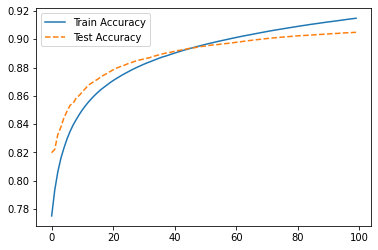

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_accuracies, label = 'Train Accuracy')
plt.plot(test_accuracies, linestyle = 'dashed', label = 'Test Accuracy')
plt.legend()
plt.show()